# The Supermax Trap: NBA Roster Construction and Winning Efficiency

**Econometric research | Grant Phillips | NC State University**

**Research question:** How are NBA regular-season wins associated with salary concentration, player contract tiers, roster depth, injuries, and analytics staffing?

This notebook accompanies the research paper *The Supermax Trap: An Analysis of Roster Construction and Winning Efficiency in the NBA* (available in `paper/`). The analysis covers **270 team-season observations across nine seasons (2017–18 through 2025–26)** and reproduces the paper's two primary ordinary least squares (OLS) specifications:

1. **Linear model:** Contract types, continuity, injuries, analytics staffing, and investment in the fourth and fifth highest-paid players.
2. **Quadratic model:** Nonlinear relationships between wins and salary shares for the top three earners, with linear terms for the fourth and fifth.

The notebook is ordered for **Run All** and uses the full author-supplied team-season CSV. Numerical values and models are reproduced from the original project, rather than retroactively changing the paper's research design.

> **Interpretation:** These are observational, in-sample associations, **not causal estimates**. The reported spending bands are exploratory ranges from the paper, **not statistically established optimal allocations or model-derived confidence intervals**. The quadratic terms for the first three players are not individually statistically significant at conventional thresholds.

## 1. Imports and reproducible dataset loading

The primary data source is the **full 38-column team-season dataset** provided with this repository (`data/NBASupermaxTrap.csv`). The notebook removes its trailing blank row in memory, normalizes the column labels used in regression formulas, and retains the **team and season identifiers**.

A 19-variable modeling extract is also retained in `data/` as an audit snapshot of the earlier paper-reproduction work; it is *not* an additional source or a separate set of observations. The code checks that both files agree on every modeling field.

Run this notebook from the repository root. It also supports execution from a `notebooks/` subfolder. The original relational MySQL export is separately available under `sql/`, and five Tableau illustrations are in `tableau/` and on the GitHub README.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)

DATA_DIR = next((path for path in [Path("data"), Path("../data")]
                 if (path / "NBASupermaxTrap.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find data/NBASupermaxTrap.csv. Run from the repository root."
    )

# The original exported file contains one fully blank trailing row.
df = pd.read_csv(DATA_DIR / "NBASupermaxTrap.csv").dropna(how="all").reset_index(drop=True)
df["Team"] = df["Team"].astype(str).str.strip()
df = df.rename(columns={"Wins(t-1)": "Wins_t_minus_1", "Time Period": "Time_Period"})

model_columns = [
    "Wins", "pct1", "pct2", "pct3", "pct4", "pct5",
    "Wins_t_minus_1", "Time_Period", "AllStars", "Analytics_Staff",
    "Injured_pct", "Max", "rk_supermax", "vt_supermax", "pct45",
]
missing_columns = sorted(set(model_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")
for column in model_columns:
    df[column] = pd.to_numeric(df[column], errors="raise")
if len(df) != 270 or df[model_columns].isna().any().any():
    raise ValueError("Expected 270 complete team-season rows for modeling")
if not np.allclose(df["pct45"], df["pct4"] + df["pct5"], atol=1e-7):
    raise ValueError("pct45 does not match pct4 + pct5")

# Confirm the original notebook's recovered modeling extract agrees row-for-row.
extract_path = DATA_DIR / "nba_modeling_data.csv"
if extract_path.exists():
    audit = pd.read_csv(extract_path)
    if not (len(audit) == len(df) and all(
        np.allclose(df[col], audit[col], atol=1e-7, rtol=1e-7)
        for col in model_columns
    )):
        raise ValueError("Modeling extract differs from the full base data")
    print("Modeling extract matches the original base CSV")

print(f"Loaded {len(df)} team-seasons, {len(df.columns)} fields")
display(df[["Year", "Team", "Wins", "pct1", "pct2", "pct3", "pct4", "pct5"]].head())

Modeling extract matches the original base CSV
Loaded 270 team-seasons, 38 fields


,Year,Team,Wins,pct1,pct2,pct3,pct4,pct5
0,2017-2018,ATL,43.0,0.168717,0.154648,0.124716,0.059864,0.049887
1,2018-2019,ATL,24.0,0.174659,0.120688,0.069516,0.051717,0.042000
2,2019-2020,ATL,29.0,0.169126,0.132599,0.118685,0.062918,0.055838
3,2020-2021,ATL,20.0,0.167102,0.154248,0.149964,0.104362,0.068555
4,2021-2022,ATL,41.0,0.173228,0.154210,0.135569,0.128817,0.064217


### Data dictionary

| Variable | Meaning |
| --- | --- |
| `Wins` | Regular-season wins (outcome) |
| `pct1`–`pct5` | Salary share allocated to each of the five highest-paid players, ranked from first to fifth |
| `pct45` | Combined salary share of fourth and fifth highest-paid players (`pct4 + pct5`) |
| `Wins_t_minus_1` | Previous season's wins |
| `Time_Period` | Season index (1–9) |
| `AllStars` | Number of All-Star players |
| `Analytics_Staff` | Estimated analytics staff headcount |
| `Injured_pct` | Share of salary expenditure lost to games missed through injury |
| `Max`, `rk_supermax`, `vt_supermax` | Counts of standard-max, rookie-supermax, and veteran-supermax contracts, respectively |

The underlying paper cites **Spotrac** for salary/contracts/wins, **RealGM** for All-Stars, and **NBAstuffer/Wayback Machine** for analytics staffing; it states that missing 2018–19 analytics staffing values were interpolated between surrounding years. See the paper for sourcing details and variable definitions.

## 2. Descriptive statistics

Start by checking the scale and distribution of the variables used in the two main models. Percentages are stored as decimals (e.g., `0.07` = 7% of team salary expenditure).

,count,mean,std,min,25%,50%,75%,max
Wins,270.0,39.774,11.889,15.000,31.000,41.500,48.750,68.000
pct1,270.0,0.217,0.044,0.059,0.191,0.219,0.247,0.338
pct2,270.0,0.171,0.044,0.040,0.140,0.174,0.203,0.289
pct3,270.0,0.123,0.035,0.037,0.099,0.121,0.143,0.220
pct4,270.0,0.091,0.025,0.021,0.074,0.090,0.110,0.169
pct5,270.0,0.068,0.020,0.021,0.054,0.067,0.080,0.118
Wins_t_minus_1,270.0,39.700,11.961,10.000,32.000,41.000,48.000,73.000
Time_Period,270.0,5.000,2.587,1.000,3.000,5.000,7.000,9.000
AllStars,270.0,0.859,0.782,0.000,0.000,1.000,1.000,3.000
Analytics_Staff,270.0,3.880,1.967,0.000,2.500,4.000,5.000,12.000


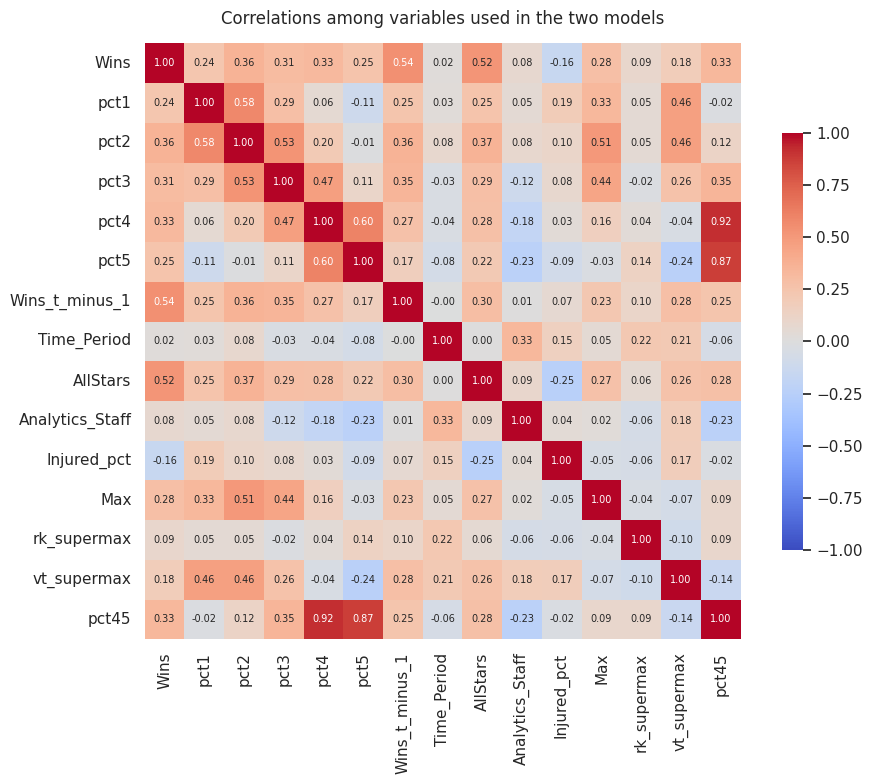

In [2]:
summary = df[model_columns].describe().T[
    ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
]
display(summary.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    df[model_columns].corr(), ax=ax, cmap="coolwarm", center=0,
    vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
    square=True, cbar_kws={"shrink": 0.7},
)
ax.set_title("Correlations among variables used in the two models", pad=14)
plt.tight_layout()
plt.show()

## 3. Linear model — contracts, organizational factors, and depth

The specification below matches the **linear model in the paper**, including lagged wins, time index, All-Star count, salary lost to injury, analytics headcount, contract classifications, and combined salary share of the fourth/fifth highest-paid players.

Coefficient interpretation is conditional on the included variables; it does not establish that changing spending or staffing *causes* additional wins.

In [3]:
LINEAR_FORMULA = (
    "Wins ~ Wins_t_minus_1 + Time_Period + AllStars + Injured_pct "
    "+ Analytics_Staff + Max + rk_supermax + vt_supermax + pct45"
)
linear_model = smf.ols(LINEAR_FORMULA, data=df).fit()


def coefficient_table(model):
    return pd.DataFrame({
        "Coefficient": model.params,
        "Std. Error": model.bse,
        "p-value": model.pvalues,
    }).round(4)


def fit_table(model):
    return pd.DataFrame({
        "Metric": ["Observations", "R-squared", "Adjusted R-squared"],
        "Value": [int(model.nobs), model.rsquared, model.rsquared_adj],
    }).round(4)

print("Linear model — coefficients")
display(coefficient_table(linear_model))
display(fit_table(linear_model))

Linear model — coefficients


,Coefficient,Std. Error,p-value
Intercept,12.3624,3.2133,0.0002
Wins_t_minus_1,0.3859,0.0518,0.0000
Time_Period,-0.0107,0.2382,0.9641
AllStars,4.4079,0.8506,0.0000
Injured_pct,-13.8150,6.2597,0.0282
Analytics_Staff,0.5039,0.3035,0.0980
Max,1.3794,0.7011,0.0502
rk_supermax,1.2879,2.9166,0.6592
vt_supermax,0.6719,1.1411,0.5565
pct45,47.8213,15.4043,0.0021


,Metric,Value
0,Observations,270.0000
1,R-squared,0.4726
2,Adjusted R-squared,0.4543


### Figure 1 — Observed versus fitted wins (in-sample)

Each dot is a team-season. This graph measures the *fit to the data used to estimate the model*, not forecast performance on unseen seasons.

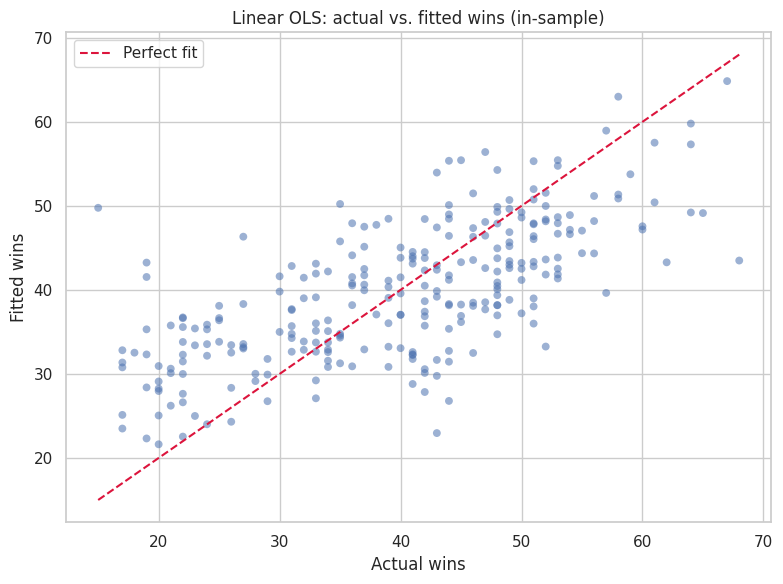

In [4]:
actual = df["Wins"].to_numpy()
fitted = linear_model.predict(df).to_numpy()
bounds = [min(actual.min(), fitted.min()), max(actual.max(), fitted.max())]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(actual, fitted, alpha=0.55, edgecolors="none", s=32)
ax.plot(bounds, bounds, "--", color="crimson", label="Perfect fit")
ax.set(
    title="Linear OLS: actual vs. fitted wins (in-sample)",
    xlabel="Actual wins", ylabel="Fitted wins",
)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Figure 2 — Win distributions by contract type

A descriptive comparison of wins among teams with different counts of standard max, rookie supermax, and veteran supermax contracts. These are unadjusted distributions, not estimates of the contract effect.

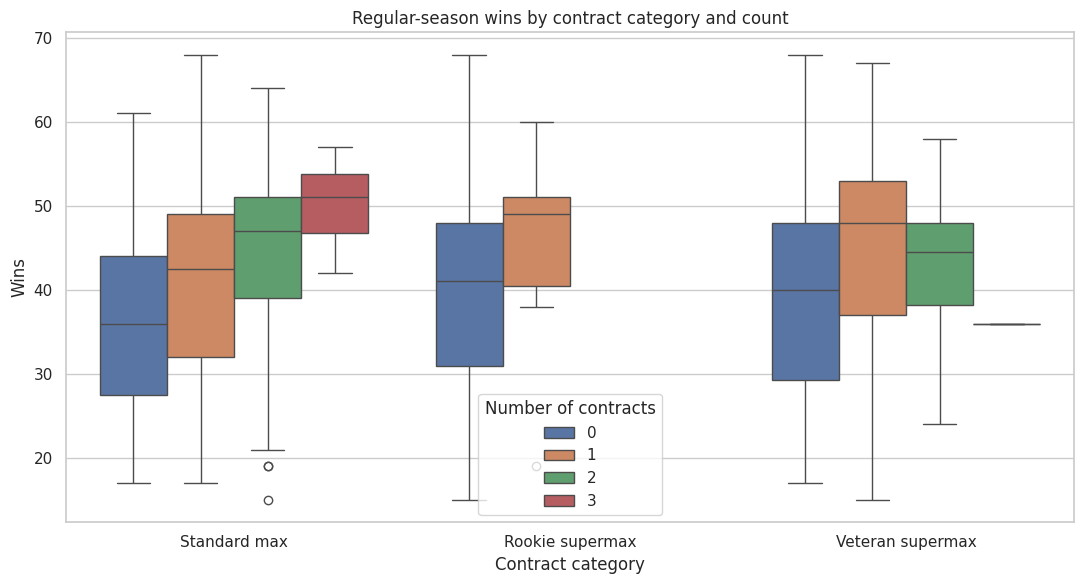

In [5]:
contract_names = {
    "Max": "Standard max",
    "rk_supermax": "Rookie supermax",
    "vt_supermax": "Veteran supermax",
}
contract_long = df[["Wins", *contract_names]].melt(
    id_vars="Wins", var_name="Contract category", value_name="Contract count"
)
contract_long["Contract category"] = contract_long["Contract category"].map(contract_names)
contract_long["Contract count"] = contract_long["Contract count"].astype(int).astype(str)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=contract_long, x="Contract category", y="Wins", hue="Contract count",
    showfliers=True, ax=ax,
)
ax.set(title="Regular-season wins by contract category and count", xlabel="Contract category")
ax.legend(title="Number of contracts", loc="best")
plt.tight_layout()
plt.show()

## 4. Quadratic model — salary allocation across the top five earners

This second OLS model reproduces the paper's quadratic specification: `pct1`–`pct3` enter both linearly and squared; `pct4` and `pct5` enter linearly. Unlike the first model, this specification does not include the controls for injuries, continuity, and analytics staffing.

**Caution:** Although the coefficient signs can suggest concave/convex shapes, the three quadratic terms are statistically imprecise here. The curves should be treated as exploratory associations, not validated optimal contracts.

In [6]:
QUADRATIC_FORMULA = (
    "Wins ~ pct1 + I(pct1**2) + pct2 + I(pct2**2) "
    "+ pct3 + I(pct3**2) + pct4 + pct5"
)
quadratic_model = smf.ols(QUADRATIC_FORMULA, data=df).fit()

print("Quadratic model — coefficients")
display(coefficient_table(quadratic_model))
display(fit_table(quadratic_model))

turning_points = []
for name in ["pct1", "pct2", "pct3"]:
    linear_coef = quadratic_model.params[name]
    squared_name = f"I({name} ** 2)"
    squared_coef = quadratic_model.params[squared_name]
    turning_points.append({
        "Salary-share variable": name,
        "Turning point (share)": -linear_coef / (2 * squared_coef),
        "Shape": "Concave" if squared_coef < 0 else "Convex",
        "Quadratic p-value": quadratic_model.pvalues[squared_name],
    })
display(pd.DataFrame(turning_points).round(4))

Quadratic model — coefficients


,Coefficient,Std. Error,p-value
Intercept,10.8200,11.0399,0.3280
pct1,130.9982,113.3479,0.2489
I(pct1 ** 2),-248.0393,261.5956,0.3439
pct2,-48.9643,115.7649,0.6727
I(pct2 ** 2),332.4151,321.8276,0.3026
pct3,-99.6096,148.6751,0.5035
I(pct3 ** 2),462.8646,526.4881,0.3801
pct4,76.6171,40.4626,0.0594
pct5,123.6491,44.5429,0.0059


,Metric,Value
0,Observations,270.0000
1,R-squared,0.2301
2,Adjusted R-squared,0.2065


,Salary-share variable,Turning point (share),Shape,Quadratic p-value
0,pct1,0.2641,Concave,0.3439
1,pct2,0.0736,Convex,0.3026
2,pct3,0.1076,Convex,0.3801


### Figures 3–7 — Partial-effect curves and descriptive salary ranges

The line varies **one salary share** while holding the other four salary shares at their sample means. Dots show the **raw observed wins**, not adjusted residuals. Shaded regions are **exploratory ranges reported in the original paper**; they are **not formal statistical confidence intervals**, and varying one share while fixing the others need not describe a feasible roster budget.

For `pct4` and `pct5`, the original paper builds these ranges from the mean ± one standard deviation among team-seasons with **50 or more wins**.

In [7]:
PAPER_RANGES = {
    "pct1": (0.225, 0.302),
    "pct2": (0.271, 0.289),
    "pct3": (0.198, 0.220),
}
elite_teams = df.loc[df["Wins"] >= 50]
for name in ["pct4", "pct5"]:
    center = elite_teams[name].mean()
    spread = elite_teams[name].std()
    PAPER_RANGES[name] = (center - spread, center + spread)

print(f"50+ win team-seasons: {len(elite_teams)}")
range_table = pd.DataFrame([
    {
        "Player salary rank": name,
        "Lower bound (%)": 100 * interval[0],
        "Upper bound (%)": 100 * interval[1],
        "Basis": "Paper-reported exploratory range" if name in ("pct1", "pct2", "pct3")
                 else "50+ win teams: mean ± 1 SD",
    }
    for name, interval in PAPER_RANGES.items()
])
display(range_table.round(1))

50+ win team-seasons: 59


,Player salary rank,Lower bound (%),Upper bound (%),Basis
0,pct1,22.5,30.2,Paper-reported exploratory range
1,pct2,27.1,28.9,Paper-reported exploratory range
2,pct3,19.8,22.0,Paper-reported exploratory range
3,pct4,7.5,12.6,50+ win teams: mean ± 1 SD
4,pct5,5.3,9.0,50+ win teams: mean ± 1 SD


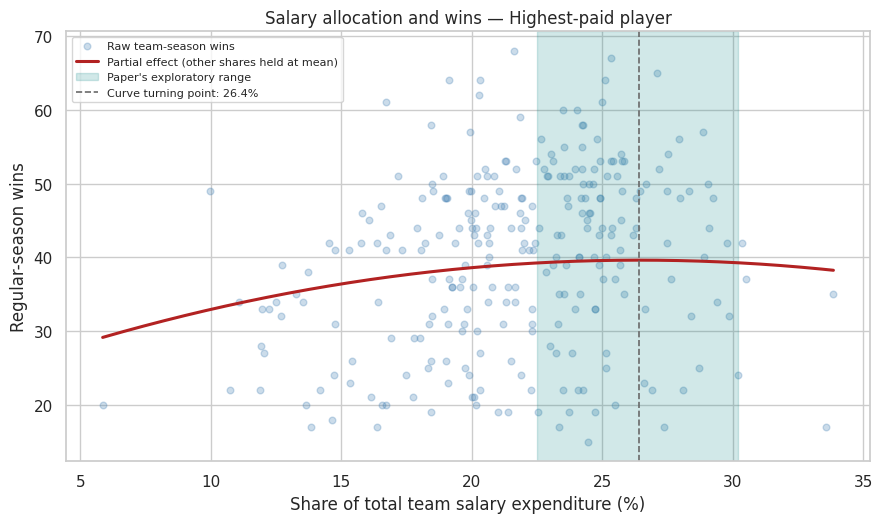

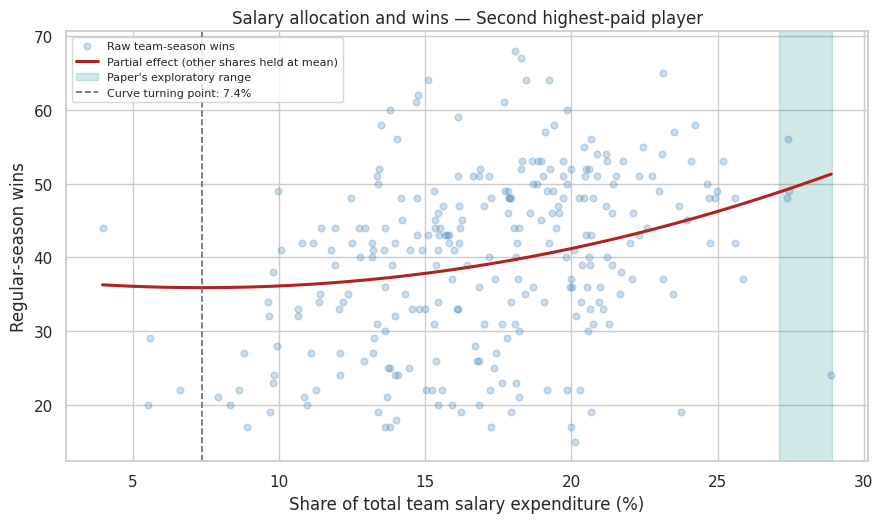

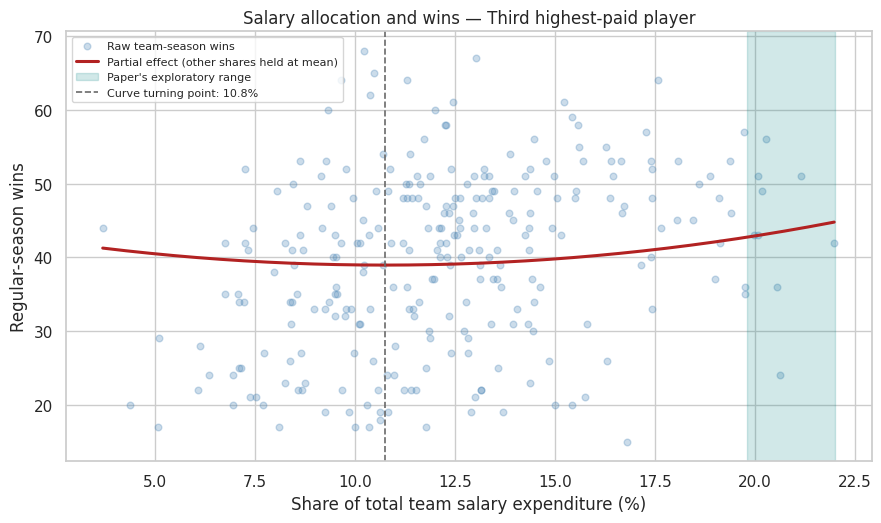

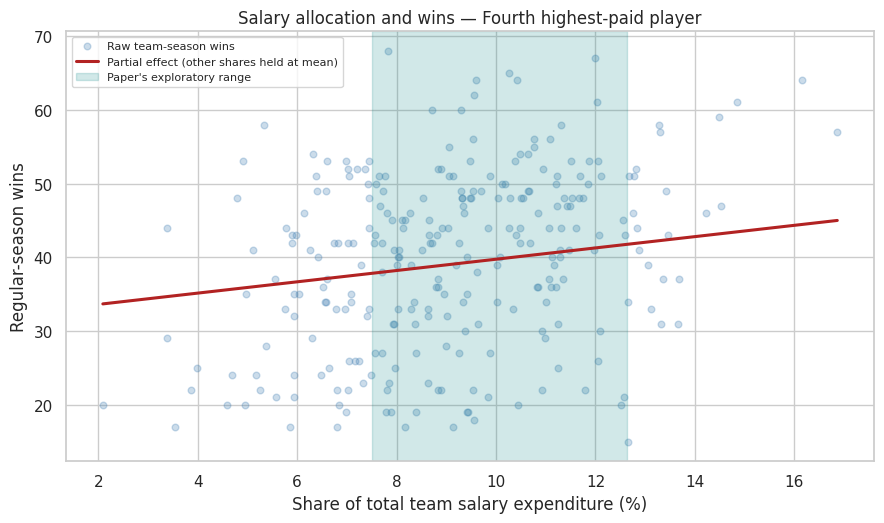

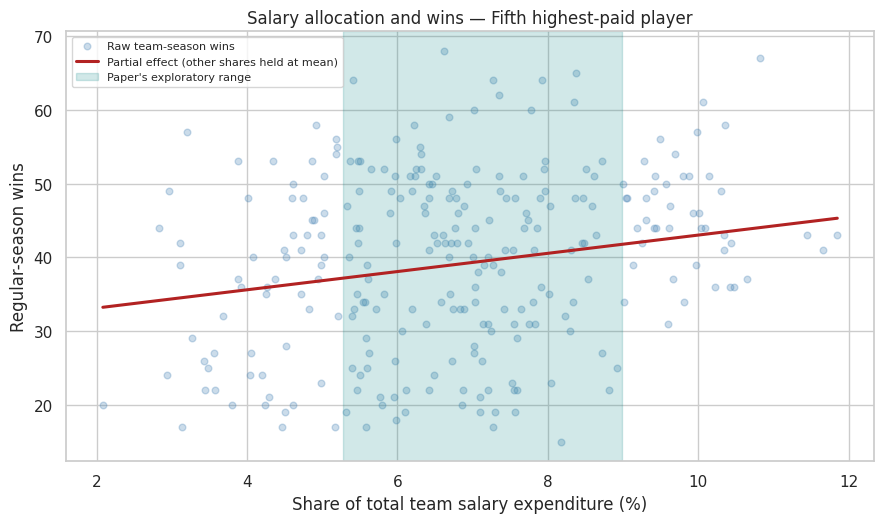

In [8]:
SALARY_SHARE_COLUMNS = ["pct1", "pct2", "pct3", "pct4", "pct5"]
RANK_LABELS = {
    "pct1": "Highest-paid player",
    "pct2": "Second highest-paid player",
    "pct3": "Third highest-paid player",
    "pct4": "Fourth highest-paid player",
    "pct5": "Fifth highest-paid player",
}


def plot_salary_partial_effect(variable, model=quadratic_model):
    """Plot an OLS partial-effect curve for a salary-share variable."""
    x_min, x_max = df[variable].min(), df[variable].max()
    grid = np.linspace(x_min, x_max, 250)
    prediction_frame = pd.DataFrame({
        col: np.full(grid.size, df[col].mean())
        for col in SALARY_SHARE_COLUMNS
    })
    prediction_frame[variable] = grid
    fitted_wins = model.predict(prediction_frame)

    fig, ax = plt.subplots(figsize=(9, 5.4))
    ax.scatter(
        df[variable] * 100, df["Wins"],
        alpha=0.28, s=23, color="steelblue", label="Raw team-season wins"
    )
    ax.plot(
        grid * 100, fitted_wins,
        color="firebrick", linewidth=2.2,
        label="Partial effect (other shares held at mean)",
    )
    lo, hi = PAPER_RANGES[variable]
    ax.axvspan(
        100 * lo, 100 * hi, alpha=0.18, color="teal",
        label="Paper's exploratory range",
    )
    if variable in ("pct1", "pct2", "pct3"):
        b1 = model.params[variable]
        b2 = model.params[f"I({variable} ** 2)"]
        point = -b1 / (2 * b2)
        if x_min <= point <= x_max:
            ax.axvline(100 * point, linestyle="--", color="dimgray", linewidth=1.2,
                       label=f"Curve turning point: {100 * point:.1f}%")

    ax.set(
        title=f"Salary allocation and wins — {RANK_LABELS[variable]}",
        xlabel="Share of total team salary expenditure (%)",
        ylabel="Regular-season wins",
    )
    ax.legend(fontsize=8, loc="best")
    plt.tight_layout()
    plt.show()


for salary_variable in SALARY_SHARE_COLUMNS:
    plot_salary_partial_effect(salary_variable)

## 5. Results and limitations

The values below are **associations from the fitted specifications**. A positive coefficient is not evidence that raising a particular player's salary would cause a team to win more games.

- **Linear model:** Adjusted R² ≈ **0.454**. `AllStars` and combined fourth/fifth-player salary share (`pct45`) have positive coefficients; `Injured_pct` has a negative coefficient. The two supermax indicators are **not statistically significant** in this specification.
- **Quadratic model:** Adjusted R² ≈ **0.207**. The fifth-earner salary share (`pct5`) has a positive coefficient with p ≈ **0.006**; the coefficients on `pct1²`, `pct2²`, and `pct3²` are **not significant** individually.

**Important limitations:** (1) Observational, in-sample OLS models do not identify causal effects; (2) salaries are imperfect proxies for player contributions; (3) salary shares are jointly constrained and correlated, so varying one share while fixing others is a modeling device rather than a realistic roster move; (4) team-specific context is omitted; and (5) the paper's reported spending bands should not be interpreted as uncertainty-qualified optima. For the detailed research discussion and data sources, see the accompanying PDF.

### Reproduction checks

The next cell checks that the cleaned data reproduces the adjusted R² values and selected coefficients reported in the original paper (up to rounding).

In [9]:
checks = {
    "Linear adjusted R²": (linear_model.rsquared_adj, 0.454),
    "Quadratic adjusted R²": (quadratic_model.rsquared_adj, 0.207),
    "Linear AllStars coefficient": (linear_model.params["AllStars"], 4.4079),
    "Linear pct45 coefficient": (linear_model.params["pct45"], 47.8213),
    "Quadratic pct5 coefficient": (quadratic_model.params["pct5"], 123.6491),
}
for label, (reproduced, reported) in checks.items():
    assert np.isclose(reproduced, reported, atol=0.001), (
        f"{label}: reproduced {reproduced:.5f}, paper {reported:.5f}"
    )
print("All five paper-reproduction checks passed.")

All five paper-reproduction checks passed.
